# Movie recommendations with ALS on MovieLens 32M

Matrix factorization with user and movie biases, trained by alternating least squares (ALS) on the full MovieLens 32M data set.
The model predicts a rating as

$$\hat r_{mn} = \mathbf{u}_m^\top \mathbf{v}_n + b^{(u)}_m + b^{(v)}_n,$$

with Gaussian noise of precision $\lambda$ and Gaussian priors of precision $\gamma$ on the biases and $\tau$ on the trait vectors. Training minimises the resulting regularised negative log-likelihood.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Practical 1
✅Download the MovieLens 32M data set and understand its README

In [ ]:
#!/bin/bash
!kaggle datasets download justsahil/movielens-32m
!unzip movielens-32m.zip

Dataset URL: https://www.kaggle.com/datasets/justsahil/movielens-32m
License(s): apache-2.0
100% 231M/231M [00:03<00:00, 64.5MB/s]

Archive:  movielens-32m.zip
  inflating: ml-32m/README.txt       
  inflating: ml-32m/checksums.txt    
  inflating: ml-32m/links.csv        
  inflating: ml-32m/movies.csv       
  inflating: ml-32m/ratings.csv      
  inflating: ml-32m/tags.csv         


In [ ]:
ratings_path = "/content/ml-32m/ratings.csv"

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# path = '/content/drive/MyDrive/AIMS/ratings.csv'

In [ ]:
# df = pd.read_csv(path)

In [ ]:
# df.head()        # Shows first 5 rows

In [ ]:
# df.shape         # (rows, columns)

What the hell?!

Shouldn't these be 32M?
Why only 1.5M rows?

### Practical 1 (for Ulrich):

* Repair Google Colab
   






In [ ]:
# df.columns

In [ ]:
# df.info()

In [ ]:
# df.describe()

In [ ]:
df = pd.read_csv(ratings_path)

## Plotting rating distributions

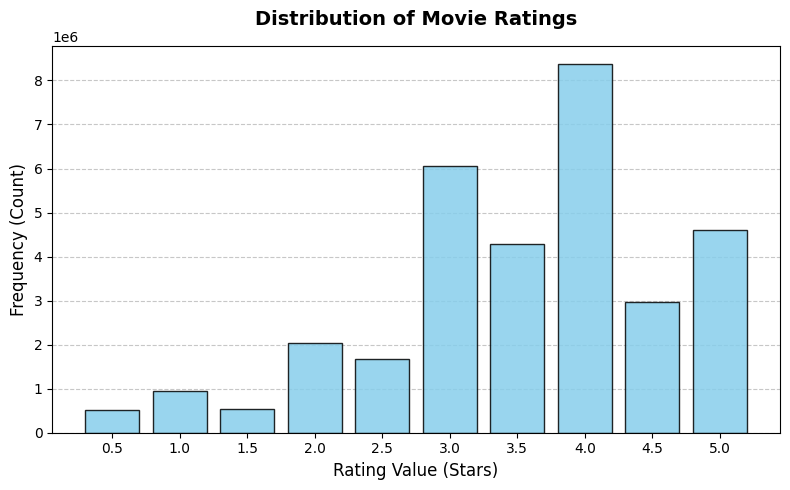

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set up bins centered on the 0.5 rating intervals
bins = np.arange(0.25, 5.75, 0.5)

plt.figure(figsize=(8, 5))
plt.hist(df['rating'], bins=bins, color='skyblue', edgecolor='black', rwidth=0.8, alpha=0.85)

# Customize the ticks to show every rating value clearly
plt.xticks(np.arange(0.5, 5.5, 0.5))
plt.title("Distribution of Movie Ratings", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Rating Value (Stars)", fontsize=12)
plt.ylabel("Frequency (Count)", fontsize=12)

# Add a clean, subtle grid behind the bars
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

I see that people are using **whole stars** more than their **half star** counterparts,

Hmmm🤔 Interesting



*   4, 3, 5, 2, 1



## Indexing

✅ Write a data structure that indexes the data

(a) by user and (b) by movie

In [ ]:
class MovieLensRatings:
  def __init__(self, df: pd.DataFrame):

    self.user_to_index = {}
    self.index_to_user = []
    self.movie_to_index = {}
    self.index_to_movie = []

    self.data_by_user = []
    self.data_by_movie = []

    self.data_by_user_train = []
    self.data_by_user_test = []

    self.data_by_movie_train = []
    self.data_by_movie_test = []

    for index, row in df.iterrows():
      if index > 100000:
        break

      # print(f"Index: {index}, user: {row['userId']}, movie: {row['movieId']}")
      user = str(int(row['userId']))
      movie = str(int(row['movieId']))
      rating = float(row['rating'])

      if user not in self.index_to_user:
        self.index_to_user.append(user)
        self.user_to_index[user] = len(self.index_to_user) - 1
        self.data_by_user.append([])
        self.data_by_user_train.append([])
        self.data_by_user_test.append([])

      if movie not in self.index_to_movie:
        self.index_to_movie.append(movie)
        self.movie_to_index[movie] = len(self.index_to_movie) - 1
        self.data_by_movie.append([])
        self.data_by_movie_train.append([])
        self.data_by_movie_test.append([])


      user_idx = self.user_to_index[user]
      movie_idx = self.movie_to_index[movie]
      self.data_by_user[user_idx].append((movie_idx, rating))
      self.data_by_movie[movie_idx].append((user_idx, rating))

      cutoff = 0.2
      if random.random() > cutoff:
        self.data_by_user_train[user_idx].append((movie_idx, rating))
        self.data_by_movie_train[movie_idx].append((user_idx, rating))
      else:
        self.data_by_user_test[user_idx].append((movie_idx, rating))
        self.data_by_movie_test[movie_idx].append((user_idx, rating))


  def get_movies_and_ratings_for_user(self, user_idx):
    return self.data_by_user[user_idx]
  def get_users_and_ratings_for_movie(self, movie_idx):
    return self.data_by_movie[movie_idx]
  def get_movies_and_ratings_for_user_train(self, user_idx):
    return self.data_by_user_train[user_idx]
  def get_users_and_ratings_for_movie_train(self, movie_idx):
    return self.data_by_movie_train[movie_idx]
  def get_movies_and_ratings_for_user_test(self, user_idx):
    return self.data_by_user_test[user_idx]
  def get_users_and_ratings_for_movie_test(self, movie_idx):
    return self.data_by_movie_test[movie_idx]


  def train_test_split(self):
    return self.data_by_user_train, self.data_by_user_test, self.data_by_movie_train, self.data_by_movie_test


In [ ]:
ratings = MovieLensRatings(df)

In [ ]:
print(ratings.get_movies_and_ratings_for_user(0))

[(0, 4.0), (1, 1.0), (2, 2.0), (3, 5.0), (4, 5.0), (5, 2.0), (6, 1.0), (7, 5.0), (8, 3.0), (9, 5.0), (10, 1.0), (11, 5.0), (12, 4.0), (13, 3.0), (14, 5.0), (15, 5.0), (16, 4.0), (17, 5.0), (18, 5.0), (19, 4.0), (20, 1.0), (21, 2.0), (22, 3.0), (23, 5.0), (24, 5.0), (25, 3.0), (26, 2.0), (27, 4.0), (28, 4.0), (29, 3.0), (30, 5.0), (31, 5.0), (32, 5.0), (33, 2.0), (34, 5.0), (35, 4.0), (36, 5.0), (37, 5.0), (38, 5.0), (39, 5.0), (40, 3.0), (41, 5.0), (42, 5.0), (43, 2.0), (44, 1.0), (45, 5.0), (46, 4.0), (47, 1.0), (48, 1.0), (49, 4.0), (50, 3.0), (51, 4.0), (52, 4.0), (53, 5.0), (54, 1.0), (55, 2.0), (56, 5.0), (57, 5.0), (58, 1.0), (59, 5.0), (60, 2.0), (61, 2.0), (62, 5.0), (63, 5.0), (64, 5.0), (65, 4.0), (66, 5.0), (67, 5.0), (68, 5.0), (69, 4.0), (70, 1.0), (71, 5.0), (72, 4.0), (73, 4.0), (74, 5.0), (75, 5.0), (76, 5.0), (77, 3.0), (78, 4.0), (79, 3.0), (80, 5.0), (81, 3.0), (82, 1.0), (83, 4.0), (84, 2.0), (85, 4.0), (86, 5.0), (87, 5.0), (88, 5.0), (89, 5.0), (90, 1.0), (91, 3.0

✅ Plot rating distributions of data Are there power laws in the data? Is it scale-free?

In [ ]:
def plot_power_laws(ratings: MovieLensRatings):
    # Movie Degree Distribution
    movie_degree_to_freq = {}
    for movie_list_of_ratings in ratings.data_by_movie:
      degree = len(movie_list_of_ratings)
      movie_degree_to_freq[degree] = movie_degree_to_freq.get(degree, 0) + 1

    # User Degree Distribution
    user_degree_to_freq = {}
    for user_list_of_ratings in ratings.data_by_user:
      degree = len(user_list_of_ratings)
      user_degree_to_freq[degree] = user_degree_to_freq.get(degree, 0) + 1

    # Plot setup
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Movie Plot
    movie_degrees = list(movie_degree_to_freq.keys())
    movie_frequencies = list(movie_degree_to_freq.values())
    ax1.scatter(movie_degrees, movie_frequencies, color='blue', alpha=0.6, label='Movies')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlabel('Degree (Number of Ratings per Movie)')
    ax1.set_ylabel('Frequency')
    ax1.set_title('Movie Rating Distribution (Power Law)')
    ax1.grid(True, which="both", linestyle='--', alpha=0.5)
    ax1.legend()

    # User Plot
    user_degrees = list(user_degree_to_freq.keys())
    user_frequencies = list(user_degree_to_freq.values())
    ax2.scatter(user_degrees, user_frequencies, color='red', alpha=0.6, label='Users')
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_xlabel('Degree (Number of Ratings per User)')
    ax2.set_ylabel('Frequency')
    ax2.set_title('User Rating Distribution (Power Law)')
    ax2.grid(True, which="both", linestyle='--', alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_power_laws_combined(ratings: MovieLensRatings):
    # Movie Degree Distribution
    movie_degree_to_freq = {}
    for movie_list_of_ratings in ratings.data_by_movie:
        degree = len(movie_list_of_ratings)
        movie_degree_to_freq[degree] = movie_degree_to_freq.get(degree, 0) + 1

    # User Degree Distribution
    user_degree_to_freq = {}
    for user_list_of_ratings in ratings.data_by_user:
        degree = len(user_list_of_ratings)
        user_degree_to_freq[degree] = user_degree_to_freq.get(degree, 0) + 1

    # Plot setup - single grid on log-log scale to capture power laws together
    plt.figure(figsize=(10, 6))

    # Plot Movies
    movie_degrees = list(movie_degree_to_freq.keys())
    movie_frequencies = list(movie_degree_to_freq.values())
    plt.scatter(movie_degrees, movie_frequencies, color='blue', alpha=0.6, label='Movies (Degree per Movie)', edgecolors='none', s=30)

    # Plot Users
    user_degrees = list(user_degree_to_freq.keys())
    user_frequencies = list(user_degree_to_freq.values())
    plt.scatter(user_degrees, user_frequencies, color='red', alpha=0.6, label='Users (Degree per User)', edgecolors='none', s=30)

    # Format axes with logarithmic scales
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Degree (Number of Ratings)', fontsize=12)
    plt.ylabel('Frequency (Count)', fontsize=12)
    plt.title('Movie & User Rating Distributions (Log-Log Scale)', fontsize=14, fontweight='bold', pad=15)
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()

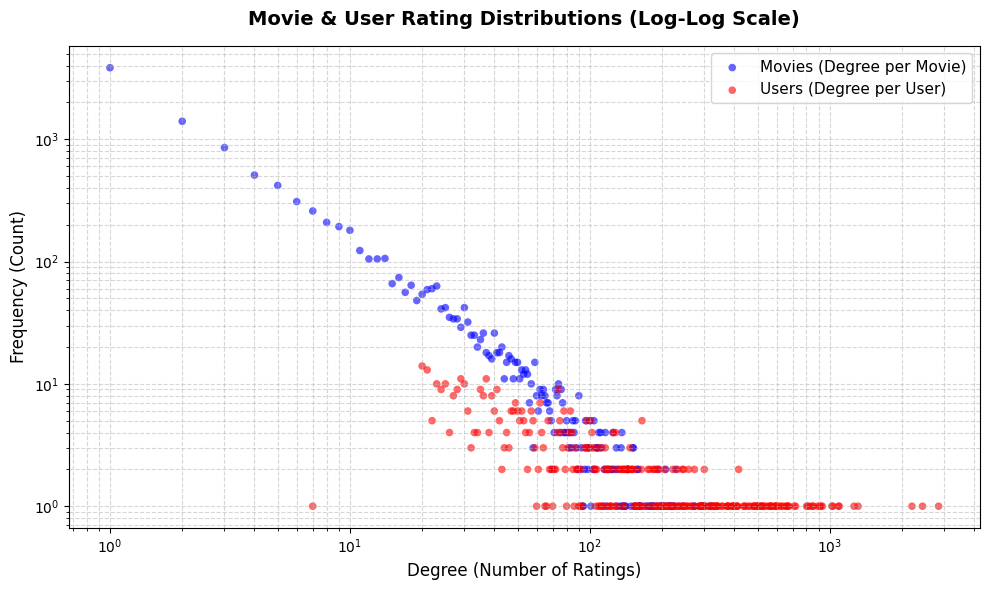

In [ ]:
plot_power_laws_combined(ratings)

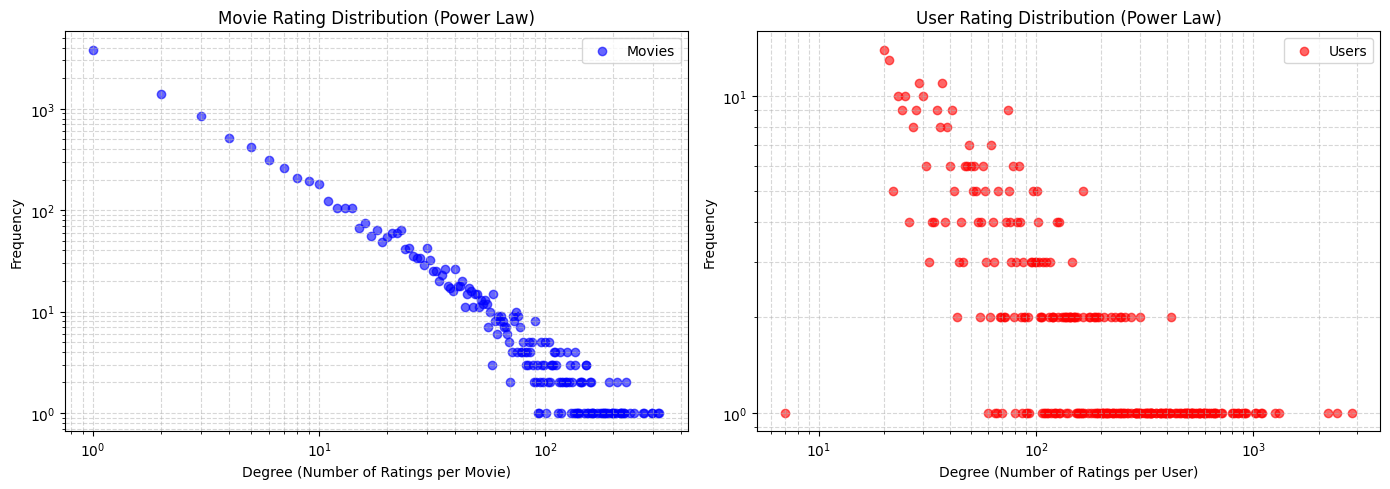

In [ ]:
plot_power_laws(ratings)


In [ ]:
# plot_power_laws_linear(ratings)

In [ ]:
print(df.head(10))
print()
print(ratings.index_to_user)
print(ratings.user_to_index)
print(ratings.data_by_user)
print()
print(ratings.index_to_movie)
print(ratings.movie_to_index)
print(ratings.data_by_movie)

## Test

In [ ]:
def get_dimensions(lst):
    if not isinstance(lst, list):
        return []
    if not lst:
        return [0]
    return [len(lst)] + get_dimensions(lst[0])


print(get_dimensions(ratings.data_by_user))
print(get_dimensions(ratings.data_by_user_train))
print(get_dimensions(ratings.data_by_user_test))
print(get_dimensions(ratings.data_by_movie))
print(get_dimensions(ratings.data_by_movie_train))
print(get_dimensions(ratings.data_by_movie_test))


# Practical 2

✅ Build a model that finds maximum likelihood estimate for user + item biases with alternating least squares

In [ ]:
M = len(ratings.index_to_user)
N = len(ratings.index_to_movie)

user_biases = np.zeros(M)
movie_biases = np.zeros(N)

epochs = 10
lambd = 0.1
gamma = 0.01
epochs_train_losses = []
epochs_test_losses = []
epochs_nll_losses = []

for epoch in range(epochs):
    # Update User Biases using only training data
    for m in range(M):
        bias = 0
        item_counter = 0
        for (n, r) in ratings.get_movies_and_ratings_for_user_train(m):
            bias += lambd * (float(r) - movie_biases[n])
            item_counter += 1
        bias /= (lambd * item_counter + gamma)
        user_biases[m] = bias

    # Update Movie Biases using only training data
    for n in range(N):
        bias = 0
        item_counter = 0
        for (m, r) in ratings.get_users_and_ratings_for_movie_train(n):
            bias += lambd * (float(r) - user_biases[m])
            item_counter += 1
        bias /= (lambd * item_counter + gamma)
        movie_biases[n] = bias

    # Training RMSE
    sqr_error_sum_train = 0
    rating_count_train = 0
    for m in range(M):
        for (n, r_mn) in ratings.get_movies_and_ratings_for_user_train(m):
            prediction = user_biases[m] + movie_biases[n]
            sqr_error = (float(r_mn) - prediction) ** 2
            sqr_error_sum_train += sqr_error
            rating_count_train += 1
    train_RMSE = (sqr_error_sum_train / rating_count_train) ** 0.5
    epochs_train_losses.append(train_RMSE)

    # Test RMSE
    sqr_error_sum_test = 0
    rating_count_test = 0
    for m in range(M):
        for (n, r_mn) in ratings.get_movies_and_ratings_for_user_test(m):
            prediction = user_biases[m] + movie_biases[n]
            sqr_error = (float(r_mn) - prediction) ** 2
            sqr_error_sum_test += sqr_error
            rating_count_test += 1
    test_RMSE = (sqr_error_sum_test / rating_count_test) ** 0.5
    epochs_test_losses.append(test_RMSE)

    # Loss function (negative log likelihood)
    rec_loss = (lambd / 2.0) * sqr_error_sum_train
    reg_user_bias = (gamma / 2.0) * np.sum(user_biases ** 2)
    reg_movie_bias = (gamma / 2.0) * np.sum(movie_biases ** 2)
    total_loss = rec_loss + reg_user_bias + reg_movie_bias
    epochs_nll_losses.append(total_loss)


NameError: name 'tau' is not defined

✅ Plot the root mean squared error over training iterations, using
`data_by_user_train`. What does it converge to?

✅ Plot the root mean squared error for `data_by_user_test` after each training
iteration. What does it converge to? Does it follow the training error?

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5.5))
epochs_range = range(1, len(epochs_train_losses) + 1)

plt.plot(epochs_range, epochs_train_losses, marker='o', linestyle='-', color='#1f77b4', label='Train RMSE', linewidth=2)
plt.plot(epochs_range, epochs_test_losses, marker='s', linestyle='--', color='#ff7f0e', label='Test RMSE', linewidth=2)

plt.title('ALS Bias Optimization: Training vs. Testing Loss', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

✅ Plot the loss function (negative log likelihood) over training iterations, using `data_by_user_train`. It should go down monotonically!

In [ ]:
# Plot loss function
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5.5))
epochs_range = range(1, len(epochs_nll_losses) + 1)

plt.plot(epochs_range, epochs_nll_losses, marker='o', linestyle='-', color='purple', label='Negative Log-Likelihood (Loss)', linewidth=2)

plt.title('ALS Bias Optimization: Negative Log-Likelihood Loss', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (NLL)', fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Practical 3

✅ Add user and item factors (latent trait vectors or matrices U and V)

✅ Build a model that finds maximum likelihood estimate for user + item biases +
latent trait vectors with alternating least squares using
data_by_user_train and data_by_movie_train


In [ ]:
M = len(ratings.index_to_user)
N = len(ratings.index_to_movie)

K = 10             # embedding dimension
I = np.identity(K) # K x K Identity matrix

user_biases = np.zeros(M)
movie_biases = np.zeros(N)

## Create a vector for each user and each movie
user_vectors = np.random.normal(0, 1/K, size=(M, K)) # std = 1/sqrt(K)   so that the vectors grow to a maximum norm of 1 (if std = 1 then vectors can grow to norm K)
movie_vectors = np.random.normal(0, 1/K, size=(N, K))

epochs = 10
lambd = 0.09
gamma = 0.1
tau = 0.9
epochs_train_losses = []
epochs_test_losses = []
epochs_nll_losses = []

for epoch in range(epochs):
  # Update User Biases using only training data
  for m in range(M):
      bias = 0
      item_counter = 0
      for (n, r) in ratings.get_movies_and_ratings_for_user_train(m):
          bias += lambd * (float(r) - (np.inner(user_vectors[m], movie_vectors[n]) + movie_biases[n]))
          item_counter += 1
      bias /= (lambd * item_counter + gamma)
      user_biases[m] = bias

  ## Update user vectors using only training data
  for m in range(M):
      left_matrix = tau * I
      right_vector = np.zeros(K)
      for (n, r) in ratings.get_movies_and_ratings_for_user_train(m):
          left_matrix += lambd * np.outer(movie_vectors[n] , movie_vectors[n])
          right_vector += lambd * movie_vectors[n] * (float(r) - user_biases[m] - movie_biases[n])
      user_vectors[m] = np.linalg.inv(left_matrix) @ right_vector


  # Update Movie Biases using only training data
  for n in range(N):
      bias = 0
      item_counter = 0
      for (m, r) in ratings.get_users_and_ratings_for_movie_train(n):
          bias += lambd * (float(r) - (np.inner(movie_vectors[n], user_vectors[m]) + user_biases[m]))
          item_counter += 1
      bias /= (lambd * item_counter + gamma)
      movie_biases[n] = bias

  ## Update movie vectors using only training data
  for n in range(N):
      left_matrix = tau * I
      right_vector = np.zeros(K)
      for (m, r) in ratings.get_users_and_ratings_for_movie_train(n):
          left_matrix += lambd * np.outer(user_vectors[m] , user_vectors[m])
          right_vector += lambd * user_vectors[m] * (float(r) - user_biases[m] - movie_biases[n])
      movie_vectors[n] = np.linalg.inv(left_matrix) @ right_vector


  # Training RMSE
  sqr_error_sum_train = 0
  rating_count_train = 0
  for m in range(M):
      for (n, r_mn) in ratings.get_movies_and_ratings_for_user_train(m):
          prediction = np.inner(user_vectors[m], movie_vectors[n]) + user_biases[m] + movie_biases[n]
          sqr_error = (float(r_mn) - prediction) ** 2
          sqr_error_sum_train += sqr_error
          rating_count_train += 1
  train_RMSE = (sqr_error_sum_train / rating_count_train) ** 0.5
  epochs_train_losses.append(train_RMSE)

  # Test RMSE
  sqr_error_sum_test = 0
  rating_count_test = 0
  for m in range(M):
      for (n, r_mn) in ratings.get_movies_and_ratings_for_user_test(m):
          prediction = np.inner(user_vectors[m], movie_vectors[n]) + user_biases[m] + movie_biases[n]
          sqr_error = (float(r_mn) - prediction) ** 2
          sqr_error_sum_test += sqr_error
          rating_count_test += 1
  test_RMSE = (sqr_error_sum_test / rating_count_test) ** 0.5
  epochs_test_losses.append(test_RMSE)

  # Loss function (negative log likelihood)
  rec_loss = (lambd / 2.0) * sqr_error_sum_train
  reg_user_bias = (gamma / 2.0) * np.sum(user_biases ** 2)
  reg_movie_bias = (gamma / 2.0) * np.sum(movie_biases ** 2)
  reg_user_vec = (tau / 2.0) * np.sum(user_vectors ** 2)
  reg_movie_vec = (tau / 2.0) * np.sum(movie_vectors ** 2)
  total_loss = rec_loss + reg_user_bias + reg_movie_bias + reg_user_vec + reg_movie_vec
  epochs_nll_losses.append(total_loss)

✅ Plot the loss function (negative log likelihood) over training iterations using `data_by_user_train`. It should go down monotonically!

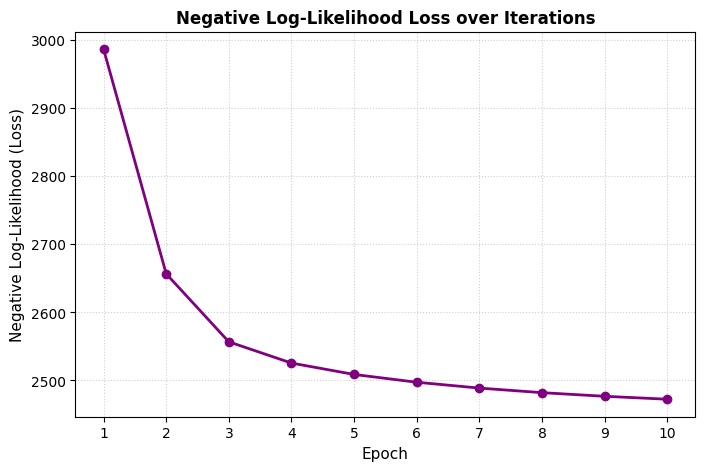

In [ ]:
# Plot the Negative Log-Likelihood Loss over epochs
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epochs_nll_losses, marker='o', color='purple', linewidth=2)
plt.title('Negative Log-Likelihood Loss over Iterations', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Negative Log-Likelihood (Loss)', fontsize=11)
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

✅ Plot the root mean squared error over training iterations using
`data_by_user_train` and `data_by_user_test` . What does it converge to?

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
epochs_range = range(1, len(epochs_train_losses) + 1)

# Train RMSE Plot
ax1.plot(epochs_range, epochs_train_losses, marker='o', linestyle='-', color='#1f77b4', label='Train RMSE', linewidth=2)
ax1.set_title('ALS Matrix Factorization: Train RMSE', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Loss (RMSE)', fontsize=11)
ax1.set_xticks(epochs_range)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=10)

# Test RMSE Plot
ax2.plot(epochs_range, epochs_test_losses, marker='s', linestyle='--', color='#ff7f0e', label='Test RMSE', linewidth=2)
ax2.set_title('ALS Matrix Factorization: Test RMSE', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Loss (RMSE)', fontsize=11)
ax2.set_xticks(epochs_range)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

# Practical 4

✅ Make your algorithm vectorized / parallel



The ratings are stored as CSR sparse matrices, and the per-user and per-movie updates are compiled and run in parallel with Numba.

## 1. Imports

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from numba import njit, prange

## 2. Load the data

In [ ]:
#!/bin/bash
!kaggle datasets download justsahil/movielens-32m
!unzip movielens-32m.zip

Dataset URL: https://www.kaggle.com/datasets/justsahil/movielens-32m
License(s): apache-2.0
100% 231M/231M [00:06<00:00, 35.8MB/s]

Archive:  movielens-32m.zip
  inflating: ml-32m/README.txt       
  inflating: ml-32m/checksums.txt    
  inflating: ml-32m/links.csv        
  inflating: ml-32m/movies.csv       
  inflating: ml-32m/ratings.csv      
  inflating: ml-32m/tags.csv         


In [ ]:
ratings_path = "/content/ml-32m/ratings.csv"
DEBUG_ROWS = None          # set to None to use all rows

df = pd.read_csv(ratings_path, dtype={"userId": "int32", "movieId": "int32",
                                      "rating": "float32", "timestamp": "int64"})
if DEBUG_ROWS is not None:
    df = df.head(DEBUG_ROWS).copy()
print("ratings:", len(df))

ratings: 32000204


## 3. Index, split and build the sparse matrices


In [ ]:
TEST_FRACTION = 0.2   # most recent 20% of each user's ratings go to test

# Map original user and movie IDs to sequential indices (0..M-1 and 0..N-1)
df["u"], user_ids = pd.factorize(df.userId)
df["m"], movie_ids = pd.factorize(df.movieId)
M, N = len(user_ids), len(movie_ids)

# Sort each user's ratings from oldest to newest
df = df.sort_values(["u", "timestamp"], kind="mergesort")

# Per-user temporal split: the last 20% (rounded up) of each user's history is test
pos    = df.groupby("u").cumcount().values                    # 0 = user's oldest rating
n_u    = df.groupby("u")["u"].transform("size").values        # ratings per user
n_test = np.ceil(TEST_FRACTION * n_u).astype(int)
is_test = pos >= n_u - n_test

def build_csr(d):
    return csr_matrix((d.rating.values.astype(np.float32),
                       (d.u.values, d.m.values)), shape=(M, N))

train_by_user  = build_csr(df[~is_test])
test_by_user   = build_csr(df[is_test])
train_by_movie = train_by_user.T.tocsr()
test_by_movie  = test_by_user.T.tocsr()

def csr3(X):
    return X.indptr, X.indices, X.data

U_csr3_train = csr3(train_by_user)
M_csr3_train = csr3(train_by_movie)
print(f"users M={M}, movies N={N}")
print(f"train ratings={train_by_user.nnz}, test ratings={test_by_user.nnz} "
      f"({100*test_by_user.nnz/len(df):.1f}% test)")

# For the paper: how many test ratings fall on movies that have no training ratings
cold = np.diff(train_by_movie.indptr) == 0
print("movies with no training ratings:", int(cold.sum()),
      "| test ratings on them:", int(test_by_movie[cold].nnz))

users M=200948, movies N=84432
train ratings=25520897, test ratings=6479307 (20.2% test)
movies with no training ratings: 13144 | test ratings on them: 19272


## 4. Data exploration

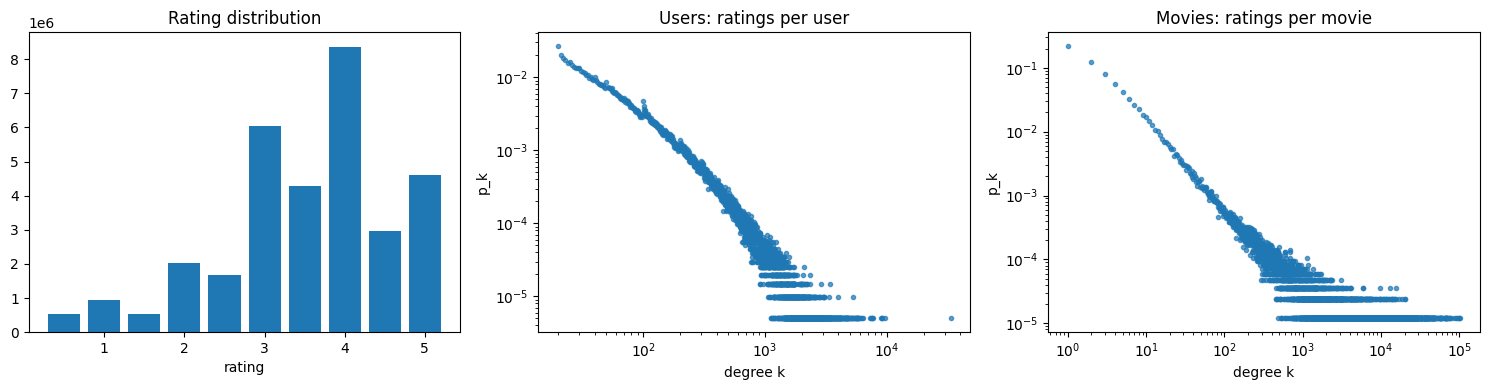

In [ ]:
user_deg  = np.bincount(df.u.values)      # ratings per user
movie_deg = np.bincount(df.m.values)      # ratings per movie

def loglog_degree(ax, deg, title):
    freq = np.bincount(deg)
    k = np.nonzero(freq)[0]
    k = k[k > 0]
    ax.loglog(k, freq[k] / len(deg), ".", alpha=0.7)
    ax.set_xlabel("degree k"); ax.set_ylabel("p_k"); ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
vals, counts = np.unique(df.rating.values, return_counts=True)
ax[0].bar(vals, counts, width=0.4); ax[0].set_title("Rating distribution"); ax[0].set_xlabel("rating")
loglog_degree(ax[1], user_deg, "Users: ratings per user")
loglog_degree(ax[2], movie_deg, "Movies: ratings per movie")
plt.tight_layout(); plt.show()

## 6. Numba kernels


- `update_biases`: $b_i = \dfrac{\lambda \sum_j (r_{ij} - \mathbf{u}_i^\top\mathbf{v}_j - b_j)}{\lambda\,|\Omega(i)| + \gamma}$
- `update_vectors`: $\mathbf{u}_i = \big(\tau I + \lambda X^\top X\big)^{-1} \lambda X^\top \mathbf{e}$, where $X$ stacks the vectors of the items rated by $i$ and $\mathbf{e}$ holds the bias-corrected ratings. Entities with no training ratings get the zero vector.
- `sq_err`: the sum of squared errors over a CSR matrix. It is used for the train RMSE, the test RMSE and the loss.

In [ ]:
@njit(parallel=True)
def update_biases(indptr, indices, data, own_vecs, other_vecs, own_biases, other_biases, lam, gam):
    for i in prange(own_biases.shape[0]):
        a = indptr[i]
        b = indptr[i + 1]
        omega = indices[a:b]
        r_vector = data[a:b]
        residuals = r_vector - other_vecs[omega] @ own_vecs[i] - other_biases[omega]   # all residuals at once
        own_biases[i] = lam * residuals.sum() / (lam * (b - a) + gam)

@njit(parallel=True)
def update_vectors(indptr, indices, data, own_vecs, other_vecs, own_biases, other_biases, lam, tau):
    K = own_vecs.shape[1]
    I = np.eye(K)
    for i in prange(own_vecs.shape[0]): # loop through users (or movies)
        a = indptr[i]
        b = indptr[i + 1]
        if b == a:
            own_vecs[i, :] = 0.0
            continue
        omega = indices[a:b]
        X = other_vecs[omega]                      # (omega, K)
        Xt = np.ascontiguousarray(X.T)            # (K, omega)
        residuals = data[a:b] - own_biases[i] - other_biases[omega]
        A = tau * I + lam * (Xt @ X)      # K x K: tau*I + lam * sum v v^T
        own_vecs[i, :] = np.linalg.solve(A, lam * (Xt @ residuals))

@njit(parallel=True)
def sq_err(indptr, indices, data, U, V, ub, mb):
    out = np.zeros(U.shape[0])
    for i in prange(U.shape[0]):
        a = indptr[i]
        b = indptr[i + 1]
        omega = indices[a:b]
        r_vector = data[a:b]
        errors = r_vector - (V[omega] @ U[i] + ub[i] + mb[omega])   # all errors for user i
        out[i] = np.sum(errors * errors)
    return out.sum()

## 7. Training loop


In [ ]:
def evaluate(U, V, ub, mb, lam, gam, tau):
    sq_tr = sq_err(*U_csr3_train, U, V, ub, mb)
    sq_te = sq_err(*csr3(test_by_user), U, V, ub, mb)
    loss = (lam / 2) * sq_tr + (gam / 2) * (ub @ ub + mb @ mb) \
         + (tau / 2) * (np.sum(U * U) + np.sum(V * V))
    return loss, np.sqrt(sq_tr / train_by_user.nnz), np.sqrt(sq_te / test_by_user.nnz)

def fit_ALS(K, lam, gam, tau, epochs, use_vectors=True, seed=0):
    rng = np.random.default_rng(seed)
    if use_vectors:
        U = rng.normal(0, 1 / K, size=(M, K))
        V = rng.normal(0, 1 / K, size=(N, K))
    else:
        U, V, tau = np.zeros((M, 1)), np.zeros((N, 1)), 0.0
    ub, mb = np.zeros(M), np.zeros(N)
    hist = {"loss": [], "train": [], "test": []}
    for epoch in range(epochs):
        t0 = time.time()
        update_biases(*U_csr3_train, U, V, ub, mb, lam, gam)                   # 1. user biases
        if use_vectors: update_vectors(*U_csr3_train, U, V, ub, mb, lam, tau)  # 2. user vectors
        update_biases(*M_csr3_train, V, U, mb, ub, lam, gam)                   # 3. movie biases
        if use_vectors: update_vectors(*M_csr3_train, V, U, mb, ub, lam, tau)  # 4. movie vectors
        loss, tr, te = evaluate(U, V, ub, mb, lam, gam, tau)
        hist["loss"].append(loss); hist["train"].append(tr); hist["test"].append(te)
        print(f"epoch {epoch+1:2d}  loss {loss:12.1f}  train RMSE {tr:.4f}  test RMSE {te:.4f}  ({time.time()-t0:.1f}s)")
    return U, V, ub, mb, hist

def plot_hist(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist["loss"], "o-"); ax[0].set_title(title + ": loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(hist["train"], "o-", label="train"); ax[1].plot(hist["test"], "o-", label="test")
    ax[1].set_title(title + ": RMSE"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 8. Biases-only model
$\lambda = 0.1$, $\gamma = 0.01$, 10 epochs.

epoch  1  loss     959849.3  train RMSE 0.8609  test RMSE 0.8867  (3.8s)
epoch  2  loss     926595.0  train RMSE 0.8458  test RMSE 0.8721  (1.1s)
epoch  3  loss     924853.9  train RMSE 0.8450  test RMSE 0.8717  (1.0s)
epoch  4  loss     924713.5  train RMSE 0.8449  test RMSE 0.8717  (1.1s)
epoch  5  loss     924678.6  train RMSE 0.8449  test RMSE 0.8717  (1.1s)
epoch  6  loss     924654.2  train RMSE 0.8449  test RMSE 0.8717  (1.1s)
epoch  7  loss     924631.4  train RMSE 0.8449  test RMSE 0.8716  (1.1s)
epoch  8  loss     924609.1  train RMSE 0.8449  test RMSE 0.8716  (1.4s)
epoch  9  loss     924586.9  train RMSE 0.8449  test RMSE 0.8716  (1.7s)
epoch 10  loss     924564.8  train RMSE 0.8449  test RMSE 0.8716  (1.7s)


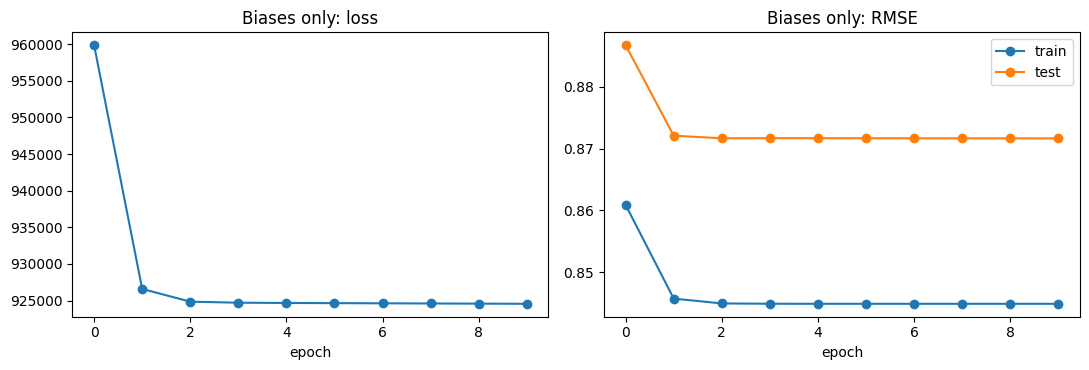

In [ ]:
_, _, ub_p2, mb_p2, hist_p2 = fit_ALS(K=1, lam=0.1, gam=0.01, tau=0.0, epochs=10, use_vectors=False)
plot_hist(hist_p2, "Biases only")

## 9. Biases and trait vectors ($K = 10$)
$\lambda = 0.09$, $\gamma = 0.1$, $\tau = 0.9$, 10 epochs.

epoch  1  loss     948824.9  train RMSE 0.8366  test RMSE 0.8897  (15.3s)
epoch  2  loss     819837.6  train RMSE 0.7592  test RMSE 0.8479  (9.0s)
epoch  3  loss     776504.0  train RMSE 0.7341  test RMSE 0.8296  (11.2s)
epoch  4  loss     757330.2  train RMSE 0.7240  test RMSE 0.8221  (11.9s)
epoch  5  loss     746621.0  train RMSE 0.7190  test RMSE 0.8186  (10.0s)
epoch  6  loss     739540.6  train RMSE 0.7162  test RMSE 0.8168  (10.1s)
epoch  7  loss     734387.1  train RMSE 0.7145  test RMSE 0.8158  (11.0s)
epoch  8  loss     730369.2  train RMSE 0.7135  test RMSE 0.8153  (11.8s)
epoch  9  loss     727048.5  train RMSE 0.7128  test RMSE 0.8150  (9.0s)
epoch 10  loss     724175.9  train RMSE 0.7124  test RMSE 0.8149  (11.3s)


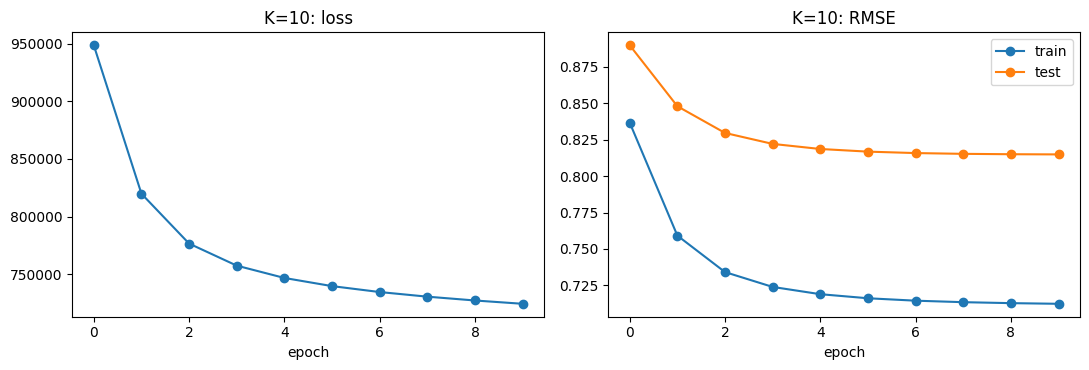

In [ ]:
K, lambd, gamma, tau = 10, 0.09, 0.1, 0.9
U, V, ub, mb, hist_p3 = fit_ALS(K=K, lam=lambd, gam=gamma, tau=tau, epochs=10)
plot_hist(hist_p3, f"K={K}")

## 10. Recommendations for a new user


In [ ]:
# titles aligned with our sequential movie indices (movie_ids[j] is the raw MovieLens id)
movies_df = pd.read_csv(ratings_path.replace("ratings.csv", "movies.csv"))
titles = movies_df.set_index("movieId").title.reindex(movie_ids).fillna("(unknown title)").values
item_counts = np.diff(train_by_movie.indptr)      # training ratings per movie

def find(query, show=10):
    hits = [j for j, t in enumerate(titles) if query.lower() in t.lower()]
    hits.sort(key=lambda j: -item_counts[j])      # most-rated first
    for j in hits[:show]:
        print(f"{j:6d}  {titles[j]}  ({item_counts[j]} train ratings)")
    return hits

## 11. Fold-in and ranking


In [ ]:
def fold_in(item_idx, rates, V, mb, lam, gam, tau, n_iter=5):
    K = V.shape[1]
    item_idx = np.asarray(item_idx)
    rates = np.asarray(rates, dtype=np.float64)
    Vu = V[item_idx]                      # vectors of the movies this user rated
    bi = mb[item_idx]                     # their biases (frozen)
    u = np.zeros(K)
    for _ in range(n_iter):
        resid = rates - Vu @ u - bi                         # bias, using the current vector
        bu = lam * resid.sum() / (lam * len(rates) + gam)
        y = rates - bi - bu                                 # vector, using the new bias
        u = np.linalg.solve(tau * np.eye(K) + lam * (Vu.T @ Vu), lam * (Vu.T @ y))
    return u, bu

def recommend(u, w=0.05, min_count=100, exclude=(), top=10):
    score = V @ u + w * mb                                   # no user bias: it can't change the ranking
    score[item_counts < min_count] = -np.inf                 # too few training ratings
    score[list(exclude)] = -np.inf                           # already rated
    best = np.argsort(-score)[:top]
    return [(titles[j], round(float(score[j]), 3), int(item_counts[j])) for j in best]

## 12. Example: a user who rated *Toy Story* five stars


In [ ]:
hits = find("Toy story")
x = hits[0]                                   # check the printout and change if needed
u, bu = fold_in([x], [5.0], V, mb, lambd, gamma, tau, n_iter=5)

for w in (1.0, 0.05):
    print(f"\n--- w = {w} ---")
    for row in recommend(u, w=w, min_count=500, exclude=[x]):
        print(row)

   462  Toy Story (1995)  (61017 train ratings)
  1267  Toy Story 2 (1999)  (27533 train ratings)
  3044  Toy Story 3 (2010)  (16949 train ratings)
  6788  Toy Story 4 (2019)  (1818 train ratings)
 12118  Toy Story of Terror (2013)  (260 train ratings)
 11770  Toy Story That Time Forgot (2014)  (254 train ratings)
  8478  Toy Story Toons: Hawaiian Vacation (2011)  (98 train ratings)
 17547  Toy Story Toons: Small Fry (2011)  (92 train ratings)
 33360  Toy Story Toons: Partysaurus Rex (2012)  (65 train ratings)

--- w = 1.0 ---
('Toy Story 2 (1999)', 2.199, 27533)
('Beauty and the Beast (1991)', 2.195, 36740)
('Toy Story 3 (2010)', 2.168, 16949)
('Lion King, The (1994)', 2.067, 44030)
('Finding Nemo (2003)', 1.989, 39999)
('Aladdin (1992)', 1.98, 45135)
('Little Mermaid, The (1989)', 1.866, 14663)
('Monsters, Inc. (2001)', 1.856, 40334)
('Incredibles, The (2004)', 1.808, 35541)
('Babe (1995)', 1.727, 31466)

--- w = 0.05 ---
('Beauty and the Beast (1991)', 2.014, 36740)
('Toy Story 2 (1